# 08 · Experiment engine, parallel backends, configuration files and CLI

**Purpose.** Compare many models in sample and out of sample with one call,
in parallel, from Python, from a JSON/TOML configuration or from the command
line.

**Out-of-sample protocol** (Lettau-Pelger; Bryzgalova et al.). For every test
period the model is re-estimated on the preceding window; weights, betas and
tangency weights from that window price the test returns; results are pooled.

| `Engine.out_of_sample` argument | Meaning |
|---|---|
| `window` | training length (rolling) or first training length (`expanding=True`) |
| `refit_every` | re-estimate every k periods (weights fixed in between) |
| `expanding` | expanding instead of rolling window |
| `oos_loadings` | `"ols"` (window betas) or `"projection"` (Lettau-Pelger) |

| `Executor` backend | When to use |
|---|---|
| `"serial"` | debugging, small problems |
| `"thread"` | large BLAS-bound tasks (NumPy releases the GIL) |
| `"process"` | many medium tasks (rolling windows, grids); scripts need `if __name__ == "__main__":` |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
data = sim.to_data("reference")
L, N = sim.xs_target.shape[1], 100
models = [
    lfm.ModelSpec("pca", {"n_factors": 3}, label="PCA"),
    lfm.ModelSpec("rppca", {"n_factors": 3, "gamma": 10}, label="RP-PCA"),
    lfm.ModelSpec("ts_target_pca", {"n_factors": 3, "gamma_ts": 15}, label="TS-alpha"),
    lfm.ModelSpec("xs_target_pca", {"n_factors": 3, "gamma_xs": L / N}, label="XS-target"),
    {
        "name": "xsts_target_pca",
        "params": {"n_factors": 3, "gamma_xs": L / N, "gamma_ts": 15},
        "label": "XS-TS",
    },
]

## 1. One call: in-sample and rolling out-of-sample

In [3]:
import time

engine = lfm.Engine(models, executor="thread", n_jobs=-1)
t0 = time.perf_counter()
result = engine.run(data, window=240, refit_every=1)
print(f"{len(models)} models x 360 windows in {time.perf_counter() - t0:.1f}s")
table = result.to_frame()
table.pivot(index="model", columns="sample", values=["sharpe_ratio", "rms_alpha"])

5 models x 360 windows in 2.4s


sharpe_ratio               rms_alpha              
sample       in-sample out-of-sample in-sample out-of-sample
model                                                       
PCA             0.3210        0.2763    0.1311        0.1742
RP-PCA          0.3742        0.2908    0.1221        0.1654
TS-alpha        0.3814        0.2911    0.1214        0.1643
XS-TS           0.3585        0.2930    0.1240        0.1674
XS-target       0.3320        0.2842    0.1284        0.1717

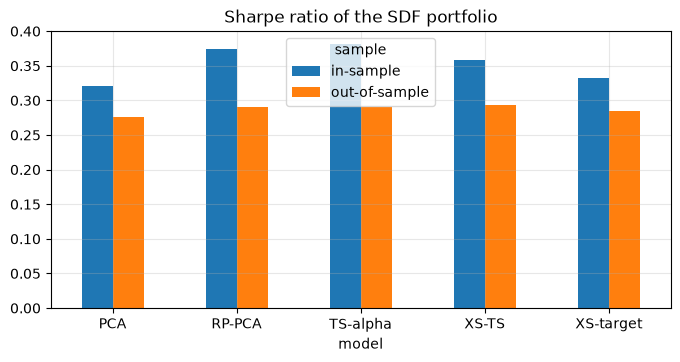

In [4]:
ax = table.pivot(index="model", columns="sample", values="sharpe_ratio").plot.bar(
    title="Sharpe ratio of the SDF portfolio", rot=0
)

## 2. Backends give identical numbers

In [5]:
serial = lfm.Engine(models[:2]).out_of_sample(data, window=240, refit_every=12).to_frame()
threads = (
    lfm.Engine(models[:2], executor="thread", n_jobs=4)
    .out_of_sample(data, window=240, refit_every=12)
    .to_frame()
)
np.allclose(serial.select_dtypes("number"), threads.select_dtypes("number"))

True

## 3. Configuration files and the command line

The CLI runs the same engine from a configuration file. Paths are relative to
the file; `output` writes a CSV. (`lfm run cfg.json --backend process` from a
terminal; called through `main([...])` here.)

In [6]:
import contextlib
import io
import json
import pathlib
import tempfile

from latent_factor_models.cli import main

work = pathlib.Path(tempfile.mkdtemp())
with contextlib.redirect_stdout(io.StringIO()):
    main(["simulate", "--T", "400", "--N", "60", "-o", str(work / "data")])
config = {
    "data": {"returns": "data/returns.csv", "factors": "data/reference.csv"},
    "models": [
        {"name": "pca", "params": {"n_factors": 3}},
        {"name": "rppca", "params": {"n_factors": 3, "gamma": 10}},
    ],
    "evaluation": {"window": 240, "refit_every": 12, "oos_loadings": "ols"},
    "execution": {"backend": "serial"},
    "output": "results.csv",
}
(work / "config.json").write_text(json.dumps(config, indent=2))
with contextlib.redirect_stderr(io.StringIO()):  # hide the CLI's 'saved to <path>' messages
    main(["run", str(work / "config.json")])
pd.read_csv(work / "results.csv")

       model        sample  sharpe_ratio     rms_alpha  unexplained_variation      total_r2
pca(n_factors=3)     in-sample        0.3303        0.1611                 0.2983        0.7361
rppca(n_factors=3,gamma=10)     in-sample        0.3934        0.1455                 0.2989        0.7357
pca(n_factors=3)  out-of-sample        0.3131        0.2225                 0.3281        0.7114
rppca(n_factors=3,gamma=10)  out-of-sample        0.3294        0.2094                 0.3292        0.7107


,model,sample,sharpe_ratio,rms_alpha,unexplained_variation,total_r2,n_windows
0,pca(n_factors=3),in-sample,0.3303,0.1611,0.2983,0.7361,NaN
1,"rppca(n_factors=3,gamma=10)",in-sample,0.3934,0.1455,0.2989,0.7357,NaN
2,pca(n_factors=3),out-of-sample,0.3131,0.2225,0.3281,0.7114,14.0
3,"rppca(n_factors=3,gamma=10)",out-of-sample,0.3294,0.2094,0.3292,0.7107,14.0


In [7]:
# Single model from CSV with estimates written to disk
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    main(
        [
            "fit",
            "rppca",
            "--returns",
            str(work / "data/returns.csv"),
            "-p",
            "n_factors=3",
            "-p",
            "gamma=10",
            "-o",
            str(work / "fit"),
        ]
    )
sorted(p.name for p in (work / "fit").iterdir())

['factors.csv', 'loadings.csv', 'summary.json', 'weights.csv']

## 4. Extending the engine with your own model

Any subclass registered with `@register` is immediately available to the
engine, the CLI and cross-validation. A spectral variant only needs `_spec`:

In [8]:
from latent_factor_models.core.registry import register
from latent_factor_models.models.spectral import SpectralFactorModel, SpectralSpec


@register()
class DownsideTargetPCA(SpectralFactorModel):
    """TS-target PCA with a down-market indicator target (illustration)."""

    name = "downside_target_pca"

    def __init__(self, n_factors: int = 1, gamma: float = 5.0) -> None:
        self.n_factors, self.gamma = n_factors, gamma

    def _spec(self, data):
        down = (data.factors[:, :1] < np.median(data.factors[:, 0])).astype(float)
        return SpectralSpec(ts_target=down, gamma_ts=self.gamma)


lfm.Engine([lfm.ModelSpec("downside_target_pca", {"n_factors": 3})]).run(data).to_frame()

,model,sample,sharpe_ratio,rms_alpha,unexplained_variation,total_r2
0,downside_target_pca(n_factors=3),in-sample,0.3391,0.1272,0.3372,0.706
